# Stroke Risk Factors: Exploratory Data Analysis

## Project Objective

This project explores demographic, lifestyle, and health-related
characteristics associated with stroke outcomes using a healthcare
dataset containing 5,110 observations.

The analysis focuses on identifying patterns in age, hypertension,
heart disease, glucose level, BMI, smoking status, work type and
residence type, followed by the development of an interactive
Power BI dashboard for exploratory healthcare analytics.

## Key Questions

1. How does stroke prevalence vary across age groups?
2. How are glucose levels distributed among stroke and non-stroke observations?
3. What patterns are observed for hypertension and heart disease?
4. How does smoking status relate to observed stroke prevalence?
5. Are there differences across work and residence categories?
6. Which variables appear most useful for distinguishing stroke
   observations in this dataset?



In [ ]:
#importing all the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# read datasdet using pandas
df = pd.read_csv(r'/content/healthcare-dataset-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.shape


(5110, 12)

In [ ]:
df.describe()


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [ ]:
# information about the dataset
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
df.nunique() #how many unique values exist in every column. This helps us distinguish categorical from continuous/numerical variables.


,0
id,5110
gender,3
age,104
hypertension,2
heart_disease,2
ever_married,2
work_type,5
Residence_type,2
avg_glucose_level,3979
bmi,418


In [ ]:
df.tail()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [ ]:
df['gender'].value_counts()



,count
gender,
Female,2994
Male,2115
Other,1


In [ ]:
df['work_type'].value_counts()


,count
work_type,
Private,2925
Self-employed,819
children,687
Govt_job,657
Never_worked,22


In [ ]:
df['Residence_type'].value_counts()


,count
Residence_type,
Urban,2596
Rural,2514


In [ ]:
df['smoking_status'].value_counts()


,count
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,885
smokes,789


In [ ]:
df['ever_married'].value_counts()

,count
ever_married,
Yes,3353
No,1757


In [ ]:
df['hypertension'].value_counts()

,count
hypertension,
0,4612
1,498


In [ ]:
df['heart_disease'].value_counts()

,count
heart_disease,
0,4834
1,276


In [ ]:
df['stroke'].value_counts() # class imbalance 0>>1

,count
stroke,
0,4861
1,249


In [ ]:
# Any missing Values in our datasets:
df.isnull().sum()


,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [ ]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_percentage

,0
id,0.000000
gender,0.000000
age,0.000000
hypertension,0.000000
heart_disease,0.000000
ever_married,0.000000
work_type,0.000000
Residence_type,0.000000
avg_glucose_level,0.000000
bmi,3.933464


In [ ]:
#checking duplicate
df.duplicated().sum()

np.int64(0)

In [ ]:
df['id'].duplicated().sum()

np.int64(0)

## Data Dictionary

| Variable | Description | Type |
|---|---|---|
| id | Unique identifier for each observation | Identifier |
| gender | Gender of the individual | Categorical |
| age | Age of the individual | Numerical |
| hypertension | Whether the individual has hypertension | Binary |
| heart_disease | Whether the individual has heart disease | Binary |
| ever_married | Whether the individual has ever been married | Categorical |
| work_type | Type of employment | Categorical |
| Residence_type | Urban or rural residence | Categorical |
| avg_glucose_level | Average glucose level | Numerical |
| bmi | Body Mass Index | Numerical |
| smoking_status | Smoking category | Categorical |
| stroke | Recorded stroke outcome | Binary target |

##  Variable Classification
### Demographic Variables
- gender
- age
- ever_married
- Residence_type

### Health Variables
- hypertension
- heart_disease
- avg_glucose_level
- bmi

### Lifestyle / Socioeconomic Variables
- smoking_status
- work_type

### Target Variable
- stroke

### Identifier
- id

In [ ]:

#table showing the quality of every variable.
#This is the part that makes the section feel like an actual data analytics project

data_quality = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})

data_quality

,Data Type,Missing Values,Missing %,Unique Values
id,int64,0,0.00,5110
gender,object,0,0.00,3
age,float64,0,0.00,104
hypertension,int64,0,0.00,2
heart_disease,int64,0,0.00,2
ever_married,object,0,0.00,2
work_type,object,0,0.00,5
Residence_type,object,0,0.00,2
avg_glucose_level,float64,0,0.00,3979
bmi,float64,201,3.93,418


In [ ]:
#Handling the missing values: (Basically it was BMI with 201 and the percenetage of 3.93%)
df['bmi'].describe()

,bmi
count,4909.000000
mean,28.893237
std,7.854067
min,10.300000
25%,23.500000
50%,28.100000
75%,33.100000
max,97.600000


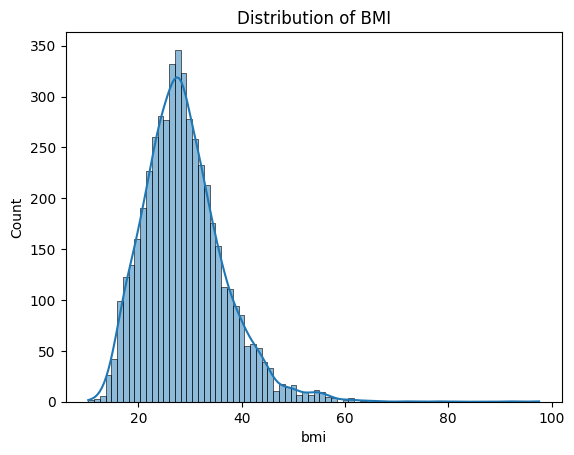

In [ ]:
sns.histplot(df['bmi'], kde= True )
plt.title("Distribution of BMI")
plt.show()


### Interpretation

The BMI distribution is positively skewed, with most observations concentrated
approximately between 20 and 35. The distribution has a noticeable right tail,
indicating the presence of observations with substantially higher BMI values.

The presence of extreme values will be further investigated using the
Interquartile Range (IQR) method rather than automatically removing them, as
unusual healthcare measurements may represent valid observations.

There are also 201 missing BMI observations, which will be addressed during
the data-cleaning stage.

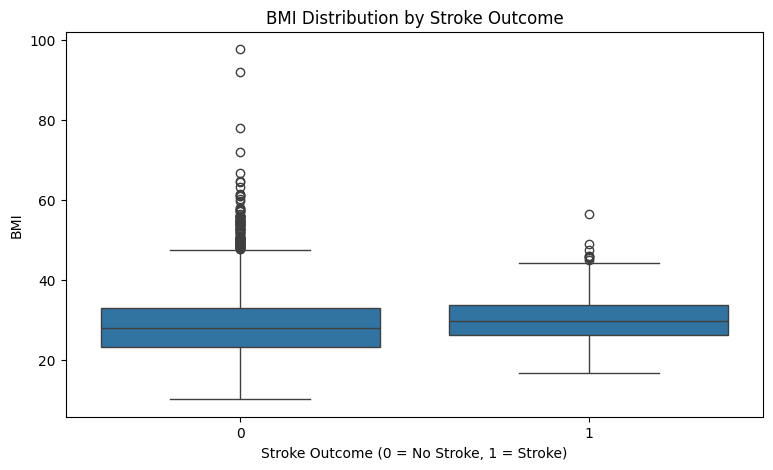

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='stroke',
    y='bmi'
)

plt.title('BMI Distribution by Stroke Outcome')
plt.xlabel('Stroke Outcome (0 = No Stroke, 1 = Stroke)')
plt.ylabel('BMI')

plt.show()

### Interpretation

The boxplot shows that the median BMI is slightly higher among observations
with a recorded stroke compared with those without a recorded stroke.
However, the two distributions show substantial overlap, indicating that BMI
alone does not clearly separate the two outcome groups.

Several high-BMI observations appear as statistical outliers in both groups,
with more extreme values visible in the non-stroke group. These observations
will be investigated rather than automatically removed, as statistical
outliers are not necessarily erroneous healthcare measurements.

In [ ]:
# IQR analysis for BMI

Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

Q1: 23.5
Q3: 33.1
IQR: 9.6
Lower Bound: 9.1
Upper Bound: 47.5


"I used the IQR method to identify potential outliers because the BMI distribution was right-skewed and contained extreme observations. Since statistical outliers are not necessarily erroneous in healthcare data, I investigated rather than automatically removing them."

In [ ]:
bmi_outliers = df[
    (df['bmi'] < lower_bound) |
    (df['bmi'] > upper_bound)
]

print("Number of BMI outliers:", len(bmi_outliers))

Number of BMI outliers: 110


In [ ]:
  bmi_outliers = df[
    (df['bmi'] < lower_bound) |
    (df['bmi'] > upper_bound)
]

bmi_outliers[['id', 'age', 'bmi', 'stroke']].sort_values(
    'bmi',
    ascending=False
).head(20)

,id,age,bmi,stroke
2128,56420,17.0,97.6,0
4209,51856,38.0,92.0,0
928,41097,23.0,78.0,0
544,545,42.0,71.9,0
1559,37759,53.0,66.8,0
358,66333,52.0,64.8,0
4188,70670,27.0,64.4,0
2764,20292,24.0,63.3,0
3825,72784,52.0,61.6,0
2840,65895,52.0,61.2,0


In [ ]:
bmi_outliers['bmi'].describe()

,bmi
count,110.000000
mean,54.181818
std,7.565302
min,47.600000
25%,49.800000
50%,52.750000
75%,55.700000
max,97.600000


In [ ]:
print("Below lower bound:",
      (df['bmi'] < lower_bound).sum())

print("Above upper bound:",
      (df['bmi'] > upper_bound).sum())

Below lower bound: 0
Above upper bound: 110


In [ ]:
bmi_outliers['stroke'].value_counts()

,count
stroke,
0,108
1,2


In [ ]:
bmi_outliers.groupby('stroke')['bmi'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
stroke,,,,,
0,108,54.208333,52.75,47.6,97.6
1,2,52.750000,52.75,48.9,56.6


In [ ]:
# Create a flag for BMI outliers

df['bmi_outlier'] = (
    (df['bmi'] < lower_bound) |
    (df['bmi'] > upper_bound)
)

df[['bmi', 'bmi_outlier']].head()

,bmi,bmi_outlier
0,36.6,False
1,NaN,False
2,32.5,False
3,34.4,False
4,24.0,False


In [ ]:
df.groupby('bmi_outlier')['stroke'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
bmi_outlier,,,
False,5000,247,0.049400
True,110,2,0.018182


"In this dataset, BMI observations identified as IQR-based statistical outliers had a lower observed stroke proportion than non-outlier BMI observations. However, the outlier group contained only two recorded stroke cases, so this comparison should not be interpreted as evidence of a protective effect or causal relationship."

### BMI Outlier Analysis

The IQR method identified 110 BMI observations as potential statistical
outliers, all of which were above the upper boundary of 47.5. No
observations fell below the lower boundary of 9.1.

The potential outliers were investigated rather than automatically removed.
Among the 110 observations, 108 had no recorded stroke and 2 had a recorded
stroke.

The observed stroke proportion was 4.94% among non-outlier BMI observations
and 1.82% among BMI outliers. However, the outlier group contained only two
recorded stroke cases, and therefore this comparison should not be interpreted
as evidence of a causal or protective relationship between high BMI and
stroke.

The identified outliers were retained because statistical unusualness alone
does not establish that a healthcare measurement is erroneous.

In [ ]:
df['bmi'].fillna(df['bmi'].median())

,bmi
0,36.6
1,28.1
2,32.5
3,34.4
4,24.0
...,...
5105,28.1
5106,40.0
5107,30.6
5108,25.6


In [ ]:
# Check whether missing BMI is associated with stroke outcome

df.groupby(df['bmi'].isna())['stroke'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
bmi,,,
False,4909,209,0.042575
True,201,40,0.199005


In [ ]:
df.groupby('gender')['bmi'].apply(
    lambda x: x.isna().sum()
)

,bmi
gender,
Female,97
Male,104
Other,0


In [ ]:
df.groupby('gender')['bmi'].apply(
    lambda x: x.isna().mean()* 100
)

,bmi
gender,
Female,3.239813
Male,4.917258
Other,0.000000


In [ ]:
bins = [0, 18, 30, 45, 60, 75, 100]
labels = ['0-18', '19-30', '31-45', '46-60', '61-75', '76+']

df['age_group'] = pd.cut(
    df['age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [ ]:
df.groupby('age_group', observed=True)['bmi'].apply(
    lambda x: x.isna().mean() * 100
)

,bmi
age_group,
0-18,2.292576
19-30,1.987768
31-45,3.530534
46-60,3.619529
61-75,6.317044
76+,7.311828


In [ ]:
df.groupby('work_type')['bmi'].apply(
    lambda x: x.isna().mean() * 100
)

,bmi
work_type,
Govt_job,4.109589
Never_worked,0.000000
Private,3.897436
Self-employed,5.372405
children,2.328967


In [ ]:
df.groupby('smoking_status')['bmi'].apply(
    lambda x: x.isna().mean() * 100
)

,bmi
smoking_status,
Unknown,3.950777
formerly smoked,5.423729
never smoked,2.114165
smokes,6.590621


BMI missingness varies across several observed characteristics, particularly age, gender and smoking status.
BMI missingness is associated with several observed characteristics and differs substantially by recorded stroke outcome.

In [ ]:
df['bmi_missing'] = df['bmi'].isna()

df['bmi_missing'].value_counts()

,count
bmi_missing,
False,4909
True,201


In [ ]:
df['bmi_imputed'] = df['bmi']

In [ ]:
group_median = df.groupby(
    ['age_group', 'gender'],
    observed=True
)['bmi'].transform('median')

df['bmi_imputed'] = df['bmi'].fillna(group_median)

In [ ]:
df['bmi_imputed'].isna().sum()

np.int64(0)

In [ ]:
df[['bmi', 'bmi_imputed']].describe()

,bmi,bmi_imputed
count,4909.000000,5110.000000
mean,28.893237,28.877260
std,7.854067,7.722338
min,10.300000,10.300000
25%,23.500000,23.700000
50%,28.100000,28.200000
75%,33.100000,32.800000
max,97.600000,97.600000


In [ ]:
print("Original missing BMI:",
      df['bmi'].isna().sum())

print("Remaining missing after imputation:",
      df['bmi_imputed'].isna().sum())

Original missing BMI: 201
Remaining missing after imputation: 0


### Missing BMI Treatment

The dataset contained 201 missing BMI observations (3.93%). Missingness
was investigated across demographic, socioeconomic and lifestyle variables.
The proportion of missing BMI values varied across age groups, gender,
work type and smoking status. Missing BMI was also observed at a different
rate across recorded stroke outcomes.

Because the BMI distribution was positively skewed, median-based
imputation was preferred over mean imputation. Missing BMI values were
imputed using the median BMI within age-group and gender subgroups.
The original BMI variable was preserved and a missingness indicator was
created to maintain information about which observations originally had
missing BMI values.

The stroke outcome was not used during imputation in order to avoid
introducing target leakage into a potential future predictive modelling
workflow.

In [ ]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [ ]:
df['bmi_imputed'].isnull().sum()

np.int64(0)

In [ ]:
df.groupby('age_group', observed=True)['stroke'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
age_group,,,
0-18,916,2,0.002183
19-30,654,0,0.000000
31-45,1048,11,0.010496
46-60,1188,59,0.049663
61-75,839,81,0.096544
76+,465,96,0.206452


The dataset shows a strong positive association between age group and recorded stroke prevalence, with substantially higher observed stroke proportions among older age groups."

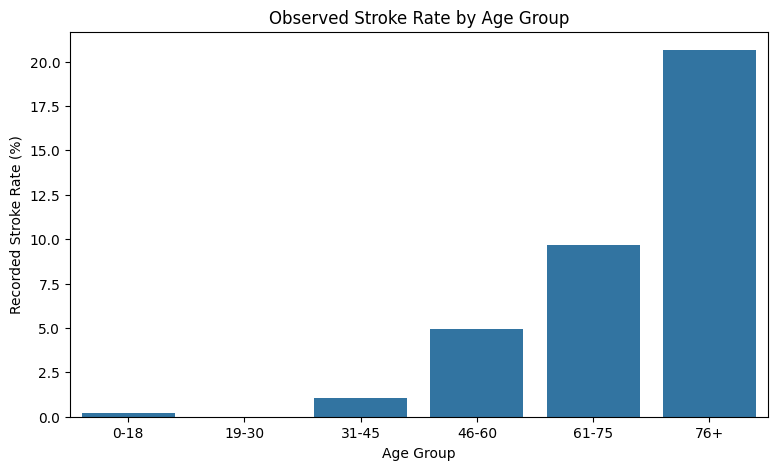

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

age_stroke = df.groupby(
    'age_group',
    observed=True
)['stroke'].mean().reset_index()

age_stroke['stroke_rate'] = age_stroke['stroke'] * 100

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_stroke,
    x='age_group',
    y='stroke_rate'
)

plt.title('Observed Stroke Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Recorded Stroke Rate (%)')

plt.show()

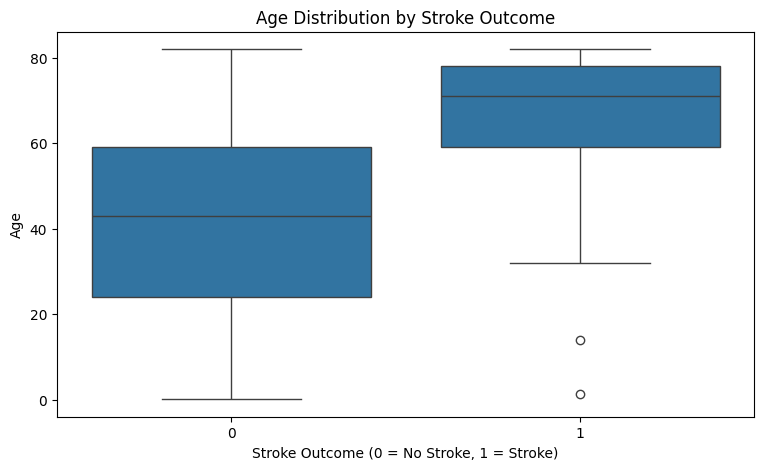

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='stroke',
    y='age'
)

plt.title('Age Distribution by Stroke Outcome')
plt.xlabel('Stroke Outcome (0 = No Stroke, 1 = Stroke)')
plt.ylabel('Age')

plt.show()

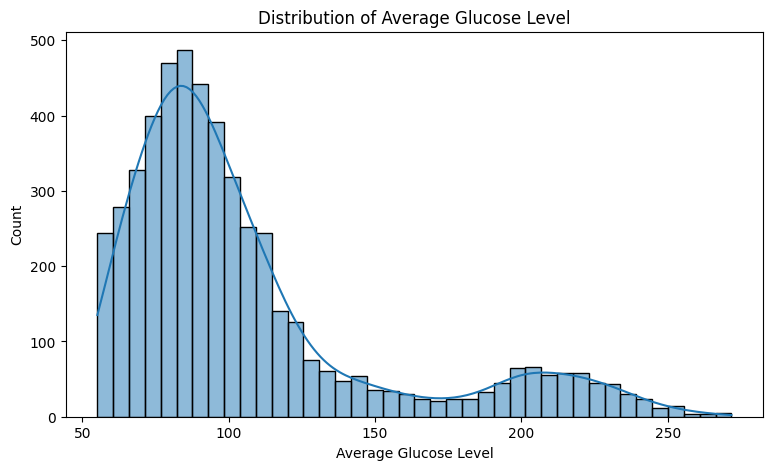

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='avg_glucose_level',
    bins=40,
    kde=True
)

plt.title('Distribution of Average Glucose Level')
plt.xlabel('Average Glucose Level')
plt.ylabel('Count')

plt.show()

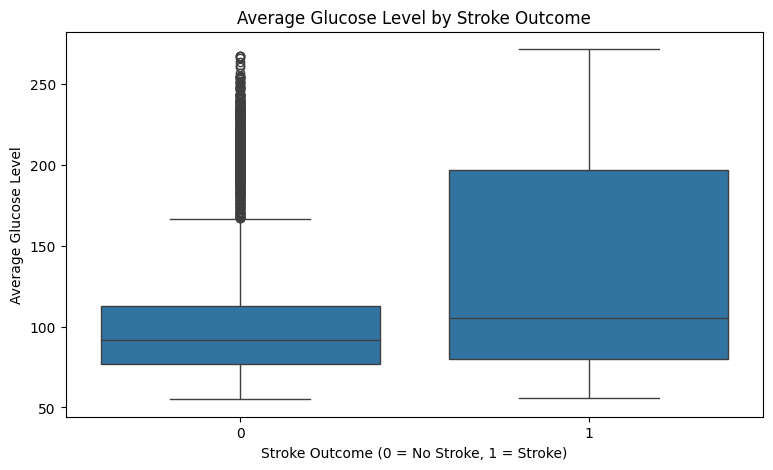

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='stroke',
    y='avg_glucose_level'
)

plt.title('Average Glucose Level by Stroke Outcome')
plt.xlabel('Stroke Outcome (0 = No Stroke, 1 = Stroke)')
plt.ylabel('Average Glucose Level')

plt.show()

Observations with recorded stroke tend to have higher and more variable average glucose levels than observations without recorded stroke.

In [ ]:
# Calculate IQR boundaries for average glucose level

Q1_glucose = df['avg_glucose_level'].quantile(0.25)
Q3_glucose = df['avg_glucose_level'].quantile(0.75)

IQR_glucose = Q3_glucose - Q1_glucose

lower_glucose = Q1_glucose - 1.5 * IQR_glucose
upper_glucose = Q3_glucose + 1.5 * IQR_glucose

print("Q1:", round(Q1_glucose, 2))
print("Q3:", round(Q3_glucose, 2))
print("IQR:", round(IQR_glucose, 2))
print("Lower bound:", round(lower_glucose, 2))
print("Upper bound:", round(upper_glucose, 2))

Q1: 77.24
Q3: 114.09
IQR: 36.84
Lower bound: 21.98
Upper bound: 169.36


In [ ]:
glucose_outliers = df[
    (df['avg_glucose_level'] < lower_glucose) |
    (df['avg_glucose_level'] > upper_glucose)
]

print("Number of glucose outliers:", len(glucose_outliers))

Number of glucose outliers: 627


IQR identifies unusual observations; it does not prove that those observations are erroneous.


In [ ]:
glucose_outliers.groupby('stroke')['avg_glucose_level'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
stroke,,,,,
0,543,211.151565,209.90,169.43,267.76
1,84,212.570000,211.42,169.67,271.74


In [ ]:
print("Below lower bound:",
      (df['avg_glucose_level'] < lower_glucose).sum())

print("Above upper bound:",
      (df['avg_glucose_level'] > upper_glucose).sum())

Below lower bound: 0
Above upper bound: 627


In [ ]:
df['glucose_outlier'] = (
    (df['avg_glucose_level'] < lower_glucose) |
    (df['avg_glucose_level'] > upper_glucose)
)

df.groupby('glucose_outlier')['stroke'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
glucose_outlier,,,
False,4483,165,0.036806
True,627,84,0.133971


"Observations with glucose levels above the IQR-based upper threshold had a higher observed stroke proportion than non-outlier observations. This represents an association in the dataset and does not establish a causal relationship."

In [ ]:
from scipy.stats import mannwhitneyu

glucose_no_stroke = df.loc[
    df['stroke'] == 0,
    'avg_glucose_level'
]

glucose_stroke = df.loc[
    df['stroke'] == 1,
    'avg_glucose_level'
]

stat, p_value = mannwhitneyu(
    glucose_no_stroke,
    glucose_stroke,
    alternative='two-sided'
)

print("U statistic:", stat)
print("p-value:", p_value)

U statistic: 471239.0
p-value: 3.6403672710893236e-09


### Statistical Analysis

A Mann–Whitney U test was used to compare average glucose levels between
observations with and without a recorded stroke. The test produced a
U statistic of 471,239.0 and a p-value of approximately 3.64 × 10⁻⁹.

The p-value is below 0.05, providing statistical evidence that the glucose
level distributions differ between the two stroke-outcome groups.

Descriptively, the stroke group showed a higher median average glucose
level and greater variability. However, the statistical association
observed in this dataset should not be interpreted as evidence that
glucose level alone causes stroke.

In [ ]:
df.groupby('hypertension')['stroke'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
hypertension,,,
0,4612,183,0.039679
1,498,66,0.132530


In [ ]:
df.groupby('heart_disease')['stroke'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
heart_disease,,,
0,4834,202,0.041787
1,276,47,0.170290


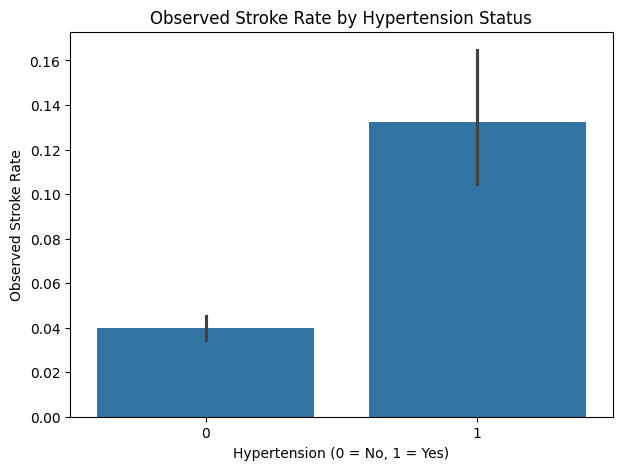

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x='hypertension',
    y='stroke'
)

plt.title('Observed Stroke Rate by Hypertension Status')
plt.xlabel('Hypertension (0 = No, 1 = Yes)')
plt.ylabel('Observed Stroke Rate')

plt.show()

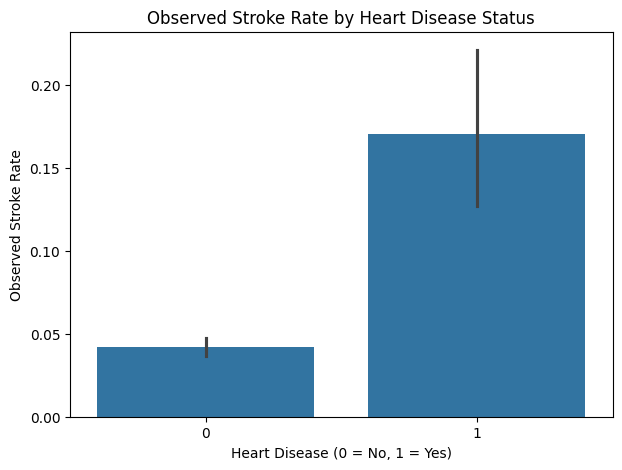

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x='heart_disease',
    y='stroke'
)

plt.title('Observed Stroke Rate by Heart Disease Status')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Observed Stroke Rate')

plt.show()

In [ ]:
from scipy.stats import chi2_contingency

table_hypertension = pd.crosstab(
    df['hypertension'],
    df['stroke']
)

chi2, p_value, dof, expected = chi2_contingency(
    table_hypertension
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 81.6053682482931
p-value: 1.661621901511823e-19


In [ ]:
table_heart = pd.crosstab(
    df['heart_disease'],
    df['stroke']
)

chi2, p_value, dof, expected = chi2_contingency(
    table_heart
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 90.25956125843324
p-value: 2.0887845685229236e-21


### Heart Disease and Stroke

Heart disease showed a statistically significant association with recorded
stroke outcome (χ² = 90.26, p < 0.001). The observed stroke proportion was
17.03% among observations with recorded heart disease, compared with 4.18%
among observations without recorded heart disease.

This indicates an association between heart disease status and recorded
stroke outcome in this dataset; however, the analysis does not establish
a causal relationship.

In [ ]:
df.groupby('smoking_status')['stroke'].agg(
    ['count', 'sum', 'mean']
).sort_values('mean', ascending=False)

,count,sum,mean
smoking_status,,,
formerly smoked,885,70,0.079096
smokes,789,42,0.053232
never smoked,1892,90,0.047569
Unknown,1544,47,0.030440


In [ ]:
table_smoking = pd.crosstab(
    df['smoking_status'],
    df['stroke']
)

chi2, p_value, dof, expected = chi2_contingency(
    table_smoking
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 29.147269191399264
p-value: 2.0853997025008455e-06


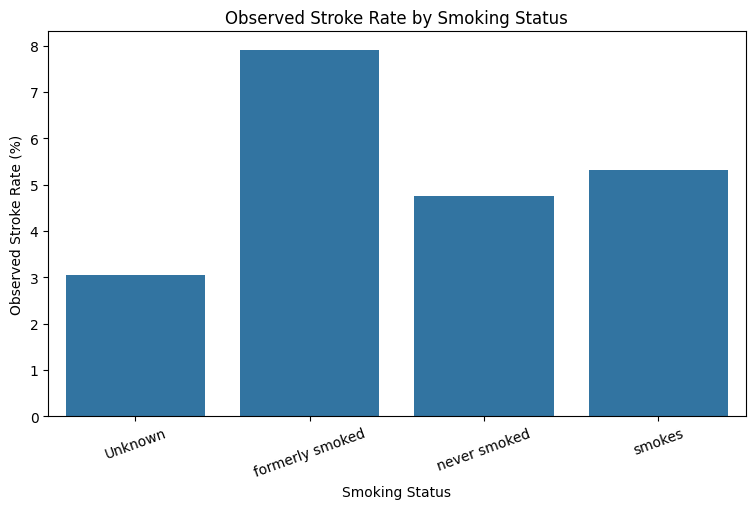

In [ ]:
smoking_rate = (
    df.groupby('smoking_status')['stroke']
    .mean()
    .mul(100)
    .reset_index(name='stroke_rate')
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=smoking_rate,
    x='smoking_status',
    y='stroke_rate'
)

plt.title('Observed Stroke Rate by Smoking Status')
plt.xlabel('Smoking Status')
plt.ylabel('Observed Stroke Rate (%)')
plt.xticks(rotation=20)

plt.show()

Smoking status was statistically associated with recorded stroke outcome (χ² = 29.15, p < 0.001). The highest observed stroke proportion was among observations classified as formerly smoked (7.91%), followed by current smokers (5.32%), never smokers (4.76%), and unknown smoking status (3.04%). These descriptive differences represent associations within this dataset and do not establish causality.

In [ ]:
df.groupby('gender')['stroke'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
gender,,,
Female,2994,141,0.047094
Male,2115,108,0.051064
Other,1,0,0.000000


In [ ]:
table_gender = pd.crosstab(
    df['gender'],
    df['stroke']
)

chi2, p_value, dof, expected = chi2_contingency(
    table_gender
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 0.47258662884530234
p-value: 0.7895490538408245


### Gender and Stroke

Gender did not show a statistically significant association with recorded
stroke outcome in this dataset (χ² = 0.47, p = 0.790). The observed stroke
proportions were 4.71% for females and 5.11% for males.

The "Other" category contained only one observation and therefore was not
interpreted separately.

Overall, the analysis did not provide sufficient statistical evidence of
a relationship between gender and recorded stroke outcome in this dataset.

In [ ]:
df.groupby('work_type')['stroke'].agg(
    ['count', 'sum', 'mean']
).sort_values('mean', ascending=False)

,count,sum,mean
work_type,,,
Self-employed,819,65,0.079365
Private,2925,149,0.050940
Govt_job,657,33,0.050228
children,687,2,0.002911
Never_worked,22,0,0.000000


In [ ]:
table_work = pd.crosstab(
    df['work_type'],
    df['stroke']
)

chi2, p_value, dof, expected = chi2_contingency(
    table_work
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 49.163511976675295
p-value: 5.397707801896119e-10


### Work Type and Stroke

Work type showed a statistically significant association with recorded
stroke outcome (χ² = 49.16, p < 0.001). The observed stroke proportion
was highest among self-employed observations (7.94%), followed by private
(5.09%) and government employment (5.02%).

The children and never-worked categories had substantially lower observed
stroke proportions, but these groups differ considerably in age and sample
size. Therefore, the observed differences should not be interpreted as
independent effects of work type or as causal relationships.

In [ ]:
df.groupby('Residence_type')['stroke'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
Residence_type,,,
Rural,2514,114,0.045346
Urban,2596,135,0.052003


In [ ]:
table_residence = pd.crosstab(
    df['Residence_type'],
    df['stroke']
)

chi2, p_value, dof, expected = chi2_contingency(
    table_residence
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)

Chi-square statistic: 1.0816367471627524
p-value: 0.29833169286876987


### Residence Type and Stroke

Residence type did not show a statistically significant association with
recorded stroke outcome (χ² = 1.08, p = 0.298). The observed stroke
proportion was 4.53% among rural observations and 5.20% among urban
observations.

The relatively small difference between the two groups and the
non-significant statistical test provide insufficient evidence of an
association between residence type and recorded stroke outcome in this
dataset.

In [ ]:
analysis_df = df.copy()

analysis_df = analysis_df[
    [
        'age',
        'bmi_imputed',
        'avg_glucose_level',
        'hypertension',
        'heart_disease',
        'gender',
        'work_type',
        'Residence_type',
        'smoking_status',
        'stroke'
    ]
].copy()

In [ ]:
analysis_df.head()

,age,bmi_imputed,avg_glucose_level,hypertension,heart_disease,gender,work_type,Residence_type,smoking_status,stroke
0,67.0,36.6,228.69,0,1,Male,Private,Urban,formerly smoked,1
1,61.0,29.6,202.21,0,0,Female,Self-employed,Rural,never smoked,1
2,80.0,32.5,105.92,0,1,Male,Private,Rural,never smoked,1
3,49.0,34.4,171.23,0,0,Female,Private,Urban,smokes,1
4,79.0,24.0,174.12,1,0,Female,Self-employed,Rural,never smoked,1


In [ ]:
analysis_encoded = pd.get_dummies(
    analysis_df,
    columns=[
        'gender',
        'work_type',
        'Residence_type',
        'smoking_status'
    ],
    drop_first=True,
    dtype=int
)

In [ ]:
analysis_encoded.head()


,age,bmi_imputed,avg_glucose_level,hypertension,heart_disease,stroke,gender_Male,gender_Other,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,36.6,228.69,0,1,1,1,0,0,1,0,0,1,1,0,0
1,61.0,29.6,202.21,0,0,1,0,0,0,0,1,0,0,0,1,0
2,80.0,32.5,105.92,0,1,1,1,0,0,1,0,0,0,0,1,0
3,49.0,34.4,171.23,0,0,1,0,0,0,1,0,0,1,0,0,1
4,79.0,24.0,174.12,1,0,1,0,0,0,0,1,0,0,0,1,0


In [ ]:
import statsmodels.api as sm

X = analysis_encoded.drop(columns='stroke')
y = analysis_encoded['stroke']

X = sm.add_constant(X)

model = sm.Logit(y, X).fit()

print(model.summary())

         Current function value: 0.154766
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                 stroke   No. Observations:                 5110
Model:                          Logit   Df Residuals:                     5094
Method:                           MLE   Df Model:                           15
Date:                Mon, 28 Sep 2026   Pseudo R-squ.:                  0.2053
Time:                        14:51:19   Log-Likelihood:                -790.85
converged:                      False   LL-Null:                       -995.19
Covariance Type:            nonrobust   LLR p-value:                 1.045e-77
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -8.0004      0.600    -13.345      0.000      -9.175      -6.825
age  

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
model_df = df[
    [
        'age',
        'bmi_imputed',
        'avg_glucose_level',
        'hypertension',
        'heart_disease',
        'gender',
        'Residence_type',
        'smoking_status',
        'stroke'
    ]
].copy()

In [ ]:
model_df = model_df[
    model_df['gender'] != 'Other'
].copy()

In [ ]:
model_encoded = pd.get_dummies(
    model_df,
    columns=[
        'gender',
        'Residence_type',
        'smoking_status'
    ],
    drop_first=True,
    dtype=int
)

In [ ]:
model_encoded.head()

,age,bmi_imputed,avg_glucose_level,hypertension,heart_disease,stroke,gender_Male,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,36.6,228.69,0,1,1,1,1,1,0,0
1,61.0,29.6,202.21,0,0,1,0,0,0,1,0
2,80.0,32.5,105.92,0,1,1,1,0,0,1,0
3,49.0,34.4,171.23,0,0,1,0,1,0,0,1
4,79.0,24.0,174.12,1,0,1,0,0,0,1,0


In [ ]:
import statsmodels.api as sm

X = model_encoded.drop(columns='stroke')
y = model_encoded['stroke']

X = sm.add_constant(X)

model = sm.Logit(y, X).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.155421
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                 stroke   No. Observations:                 5109
Model:                          Logit   Df Residuals:                     5098
Method:                           MLE   Df Model:                           10
Date:                Mon, 28 Sep 2026   Pseudo R-squ.:                  0.2021
Time:                        14:55:59   Log-Likelihood:                -794.05
converged:                       True   LL-Null:                       -995.14
Covariance Type:            nonrobust   LLR p-value:                 3.241e-80
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -7.6032      0.535    -14.220     

In [ ]:
import numpy as np
import pandas as pd

odds_ratios = np.exp(model.params)

confidence_intervals = np.exp(model.conf_int())

results = pd.DataFrame({
    'Odds Ratio': odds_ratios,
    'CI Lower': confidence_intervals[0],
    'CI Upper': confidence_intervals[1],
    'p-value': model.pvalues
})

results.round(4)

,Odds Ratio,CI Lower,CI Upper,p-value
const,0.0005,0.0002,0.0014,0.0000
age,1.0720,1.0609,1.0833,0.0000
bmi_imputed,1.0016,0.9800,1.0238,0.8840
avg_glucose_level,1.0041,1.0017,1.0064,0.0006
hypertension,1.4869,1.0776,2.0517,0.0157
heart_disease,1.3536,0.9324,1.9653,0.1114
gender_Male,1.0172,0.7711,1.3420,0.9038
Residence_type_Urban,1.0947,0.8355,1.4342,0.5116
smoking_status_formerly smoked,1.0400,0.6942,1.5582,0.8491
smoking_status_never smoked,0.8540,0.5816,1.2540,0.4208


Observations with recorded hypertension had approximately 1.49 times the estimated odds of recorded stroke compared with observations without recorded hypertension.

"Although heart disease showed a statistically significant bivariate association with recorded stroke outcome, its association was not statistically significant after adjustment for the other variables included in the logistic regression model."
So this model provides no statistical evidence of an independent association between BMI and recorded stroke outcome after adjustment for the included variables.

In [ ]:
final_results = results.drop(index='const').copy()

final_results['Significance'] = np.where(
    final_results['p-value'] < 0.05,
    'Statistically significant',
    'Not statistically significant'
)

final_results = final_results.round({
    'Odds Ratio': 3,
    'CI Lower': 3,
    'CI Upper': 3,
    'p-value': 4
})

final_results

,Odds Ratio,CI Lower,CI Upper,p-value,Significance
age,1.072,1.061,1.083,0.0000,Statistically significant
bmi_imputed,1.002,0.980,1.024,0.8840,Not statistically significant
avg_glucose_level,1.004,1.002,1.006,0.0006,Statistically significant
hypertension,1.487,1.078,2.052,0.0157,Statistically significant
heart_disease,1.354,0.932,1.965,0.1114,Not statistically significant
gender_Male,1.017,0.771,1.342,0.9038,Not statistically significant
Residence_type_Urban,1.095,0.836,1.434,0.5116,Not statistically significant
smoking_status_formerly smoked,1.040,0.694,1.558,0.8491,Not statistically significant
smoking_status_never smoked,0.854,0.582,1.254,0.4208,Not statistically significant
smoking_status_smokes,1.162,0.740,1.825,0.5147,Not statistically significant


In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Predicted probability of stroke
y_prob = model.predict(X)

# ROC-AUC
auc_score = roc_auc_score(y, y_prob)

print("ROC-AUC:", auc_score)

ROC-AUC: 0.8452831903746675


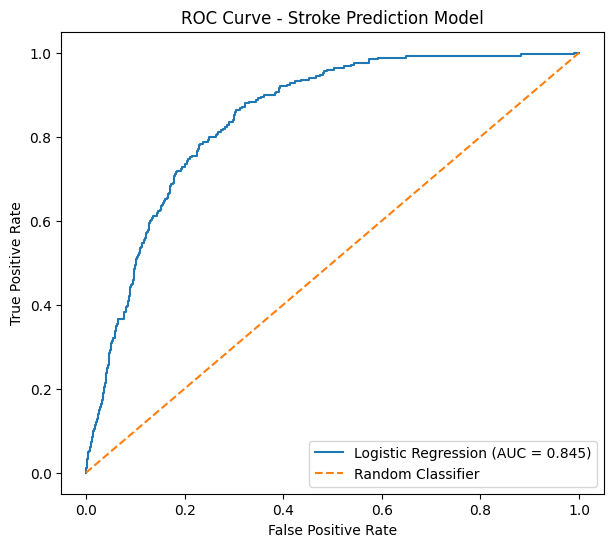

In [ ]:
fpr, tpr, thresholds = roc_curve(y, y_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {auc_score:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Stroke Prediction Model')
plt.legend()

plt.show()

### ROC-AUC Evaluation

The logistic regression model achieved an in-sample ROC-AUC of 0.845.
The ROC curve lies substantially above the random-classifier reference
line, indicating that the model has useful discriminatory ability on the
data used for model fitting.

Because this evaluation was performed on the training data, the value
should be interpreted as an in-sample performance measure rather than
as evidence of performance on unseen observations.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

X_ml = model_encoded.drop(columns='stroke')
y_ml = model_encoded['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X_ml,
    y_ml,
    test_size=0.20,
    random_state=42,
    stratify=y_ml
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 4087
Testing observations: 1022


In [ ]:
ml_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

ml_model.fit(X_train, y_train)

y_test_prob = ml_model.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(
    y_test,
    y_test_prob
)

print("Test ROC-AUC:", test_auc)

Test ROC-AUC: 0.8379012345679012


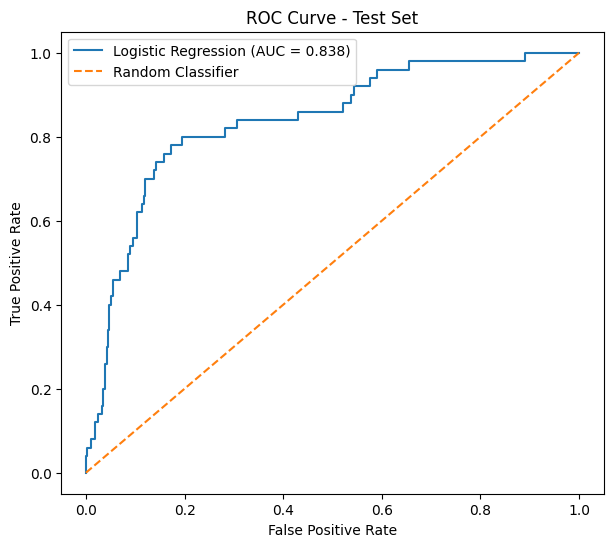

In [ ]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {test_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()

plt.show()

### Model Evaluation — ROC-AUC

The logistic regression model achieved a ROC-AUC of 0.838 on the
held-out test set. The ROC curve remained substantially above the
random-classifier reference line, indicating that the model showed
useful discrimination between the two stroke-outcome classes on unseen
test observations.

The test-set AUC was slightly lower than the in-sample AUC of 0.845,
which is expected when evaluating the model on previously unseen data.
The test-set result provides a more appropriate estimate of the model's
generalization performance.

In [ ]:
powerbi_df = df[
    [
        'id',
        'age',
        'gender',
        'hypertension',
        'heart_disease',
        'avg_glucose_level',
        'bmi_imputed',
        'stroke',
        'work_type',
        'Residence_type',
        'smoking_status',
        'age_group'
    ]
].copy()

powerbi_df.to_csv(
    'stroke_analysis_cleaned.csv',
    index=False
)

print(powerbi_df.shape)
powerbi_df.head()

(5110, 12)


,id,age,gender,hypertension,heart_disease,avg_glucose_level,bmi_imputed,stroke,work_type,Residence_type,smoking_status,age_group
0,9046,67.0,Male,0,1,228.69,36.6,1,Private,Urban,formerly smoked,61-75
1,51676,61.0,Female,0,0,202.21,29.6,1,Self-employed,Rural,never smoked,61-75
2,31112,80.0,Male,0,1,105.92,32.5,1,Private,Rural,never smoked,76+
3,60182,49.0,Female,0,0,171.23,34.4,1,Private,Urban,smokes,46-60
4,1665,79.0,Female,1,0,174.12,24.0,1,Self-employed,Rural,never smoked,76+
